In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [2]:
df = pd.read_csv('Churn_Modelling.csv')

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**(Customer Segmentation + Customer Value Prediction + Churn Risk Analytics)
Business Problem:
Banks need to identify valuable customers, understand customer behavior,
predict customer value, detect churn risk, and design personalized retention
and cross-selling strategies.**

In [4]:
df.shape

(10000, 14)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [6]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [7]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [8]:
df["Geography"].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

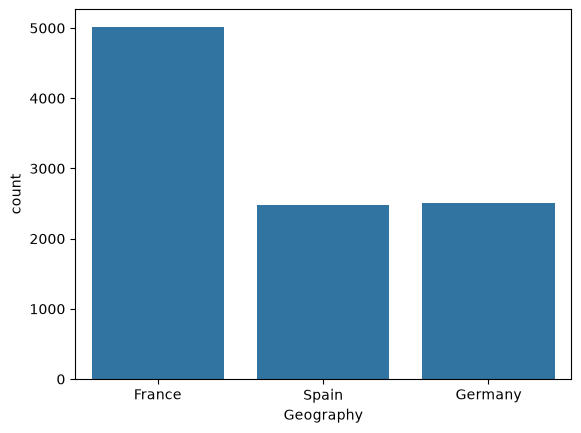

In [9]:
sns.countplot(x="Geography", data=df)
plt.show()

In [10]:
churn_geo=df.groupby('Geography')["Exited"].mean().reset_index()

In [11]:
churn_geo["Exited"]=churn_geo["Exited"]*100

In [12]:
churn_geo

,Geography,Exited
0,France,16.154767
1,Germany,32.443204
2,Spain,16.673395


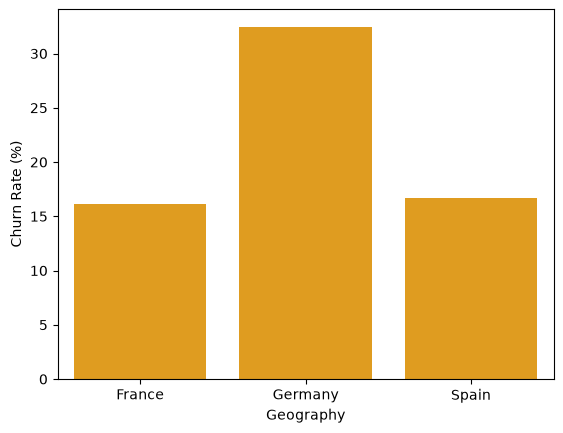

In [13]:
sns.barplot(churn_geo, x="Geography",y="Exited",color="orange")
plt.xlabel("Geography")
plt.ylabel("Churn Rate (%)")
plt.show()

In [14]:
df["Gender"].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

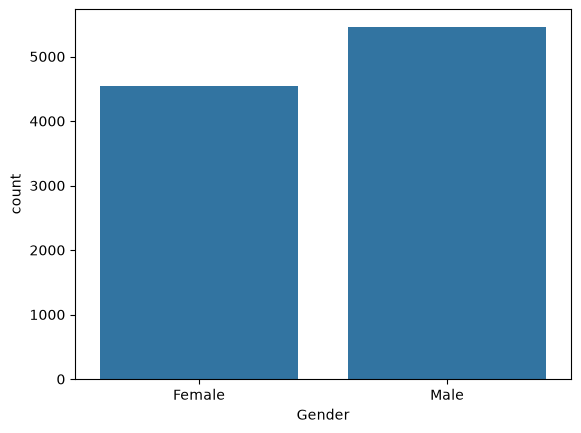

In [15]:
sns.countplot(x=df["Gender"],data=df)
plt.show()

In [16]:
churn_gen=df.groupby('Gender')["Exited"].mean().reset_index()

In [17]:
churn_gen["Exited"]=churn_gen["Exited"]*100


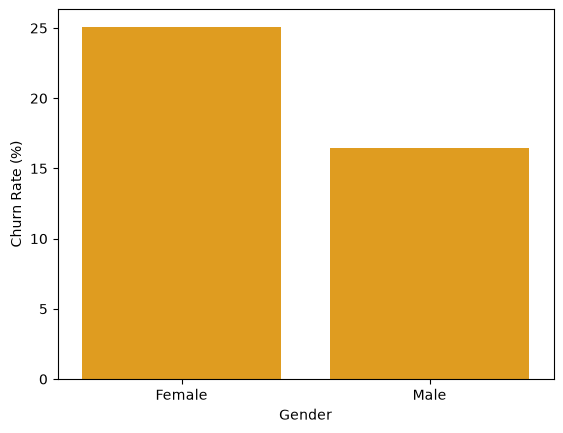

In [18]:
sns.barplot(churn_gen, x="Gender",y="Exited",color="orange")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.show()    

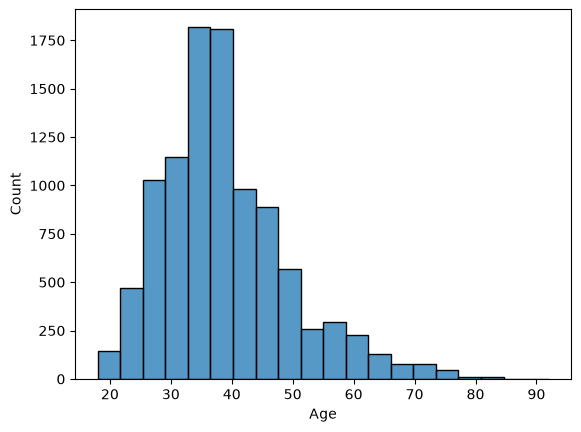

In [19]:
sns.histplot(df["Age"], bins=20)
plt.show()

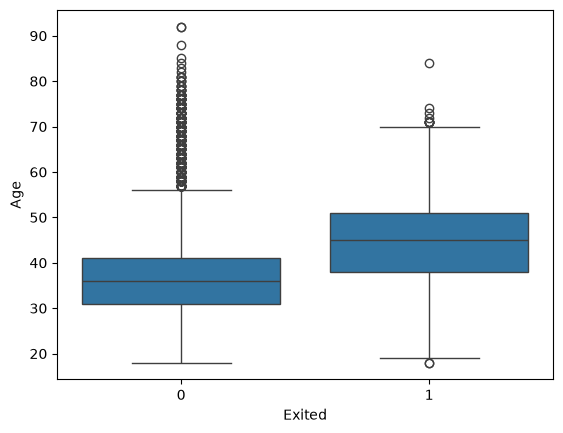

In [20]:
sns.boxplot(data=df, x="Exited", y="Age")
plt.show()

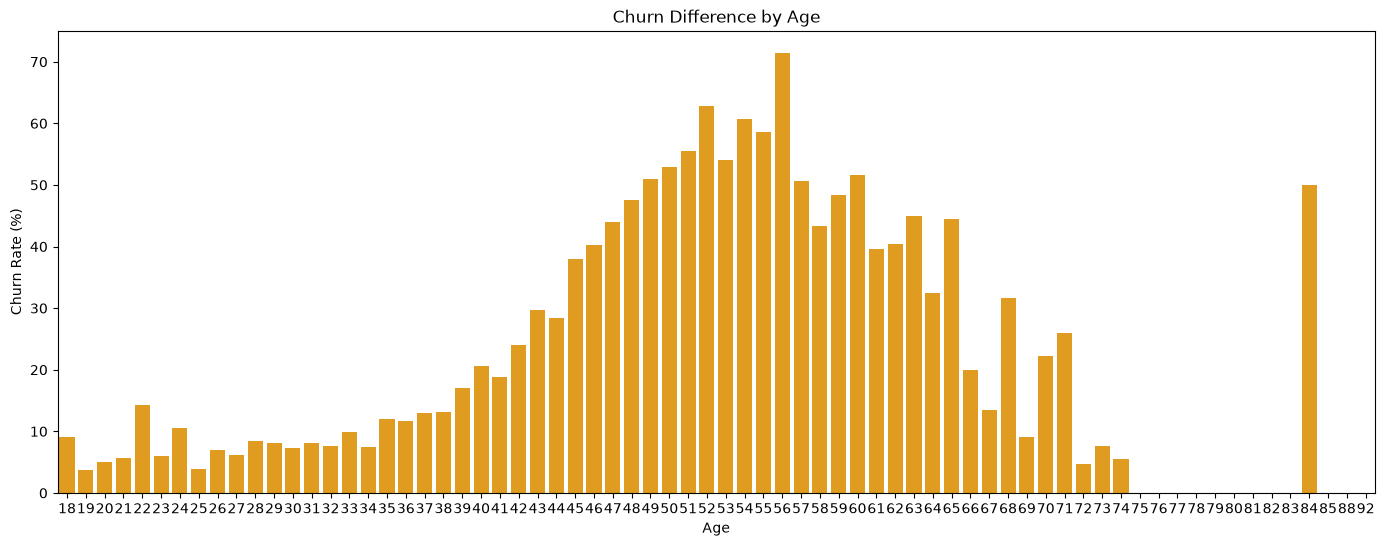

In [21]:
churn_age = df.groupby('Age')["Exited"].mean().reset_index()

churn_age["Exited"] = churn_age["Exited"] * 100

plt.figure(figsize=(17,6))
sns.barplot(data=churn_age, x="Age", y="Exited", color="orange")

plt.xlabel("Age")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Difference by Age")

plt.show()

In [22]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "65+"
    ]
)

In [23]:
age_churn = df.groupby("AgeGroup", observed=False)["Exited"].mean() * 100

age_churn

AgeGroup
18-25     7.528642
26-35     8.498024
36-45    19.619914
46-55    50.572082
56-65    48.320896
65+      13.257576
Name: Exited, dtype: float64

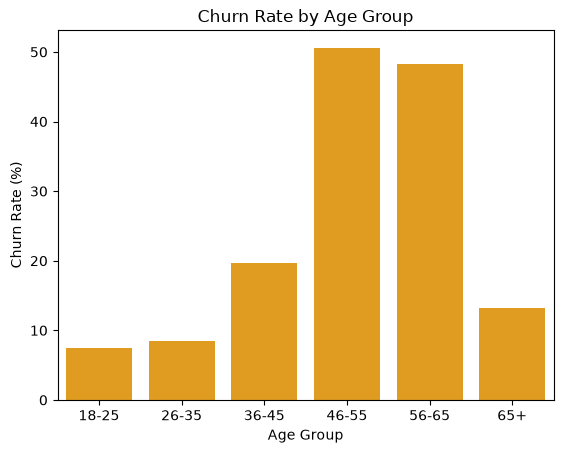

In [24]:
sns.barplot(x=age_churn.index, y=age_churn.values, color="orange")

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.show()

In [25]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeGroup
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,36-45
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,36-45
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,36-45
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,36-45
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,36-45


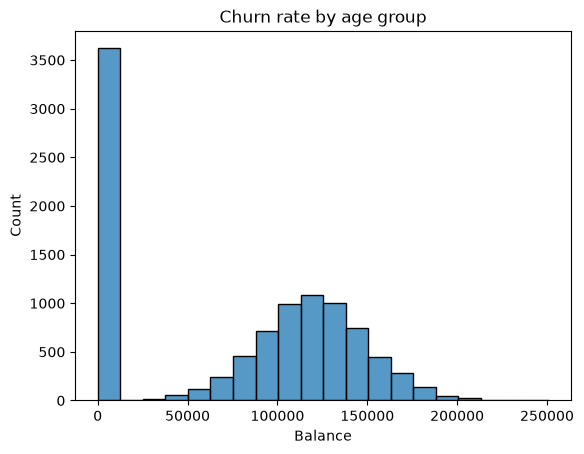

In [26]:
sns.histplot(df["Balance"], bins=20)
plt.title("Churn rate by age group")
plt.show()

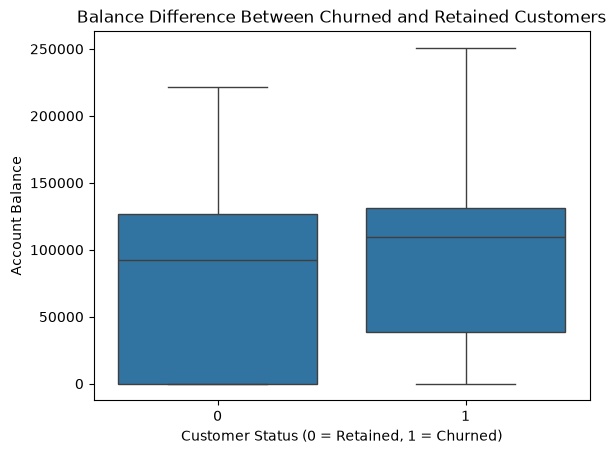

In [27]:
sns.boxplot(data=df, x="Exited", y="Balance")

plt.xlabel("Customer Status (0 = Retained, 1 = Churned)")
plt.ylabel("Account Balance")
plt.title("Balance Difference Between Churned and Retained Customers")

plt.show()

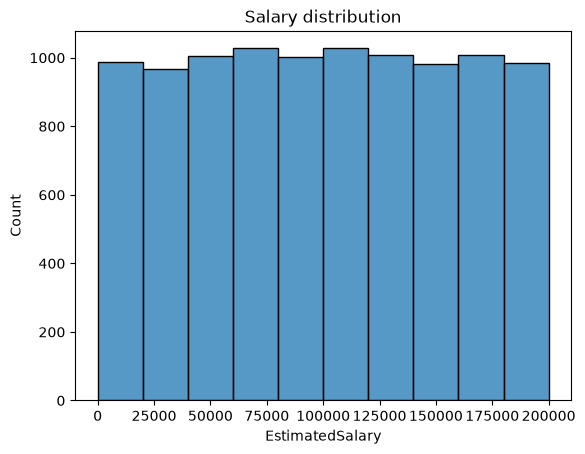

In [28]:
sns.histplot(df["EstimatedSalary"], bins=10)
plt.title("Salary distribution")
plt.show()

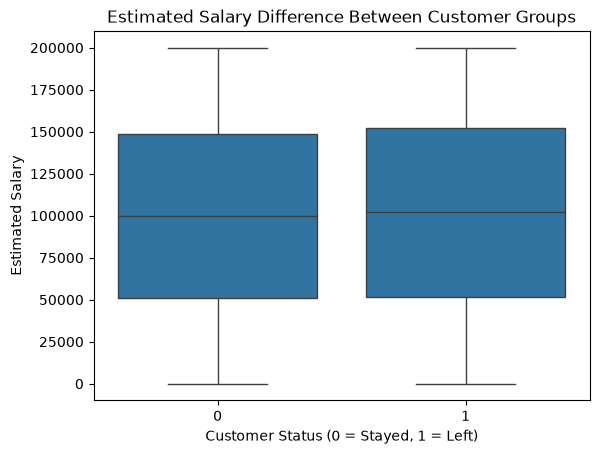

In [29]:
sns.boxplot(data=df, x="Exited", y="EstimatedSalary")
plt.xlabel("Customer Status (0 = Stayed, 1 = Left)")
plt.ylabel("Estimated Salary")
plt.title("Estimated Salary Difference Between Customer Groups")
plt.show()

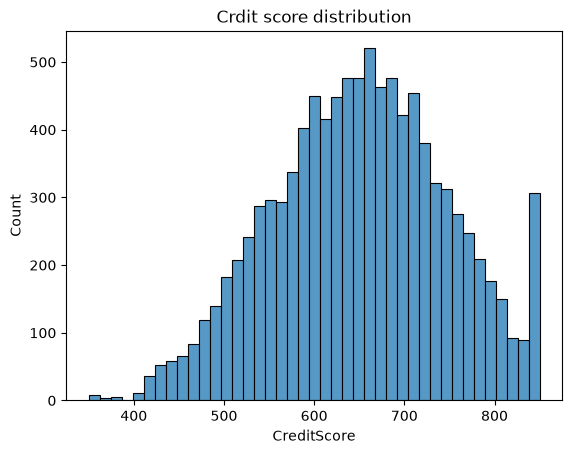

In [30]:
sns.histplot(data=df,x=df["CreditScore"])
plt.title("Crdit score distribution")
plt.show()

In [31]:
def categorize_credit(score):
    if score < 580:
        return "Low"
    elif score < 670:
        return "Fair"
    elif score < 740:
        return "Good"
    elif score < 800:
        return "Very Good"
    else:
        return "Excellent"

In [32]:
df["CredscoreCategory"]=df["CreditScore"].apply(categorize_credit)

In [33]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeGroup,CredscoreCategory
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,36-45,Fair
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,36-45,Fair
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,36-45,Low
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,36-45,Good
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,36-45,Excellent


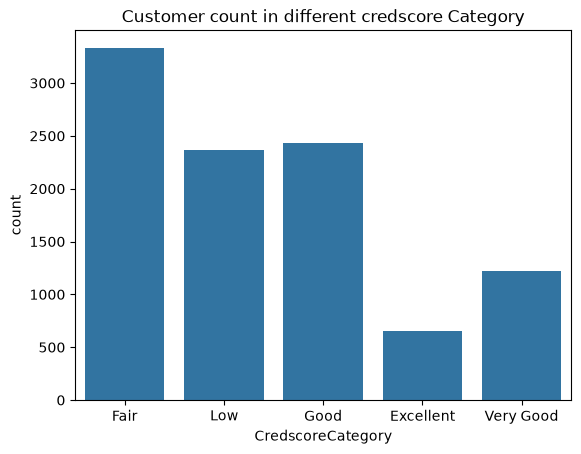

In [34]:
sns.countplot(data=df,x="CredscoreCategory")
plt.title("Customer count in different credscore Category")
plt.show()

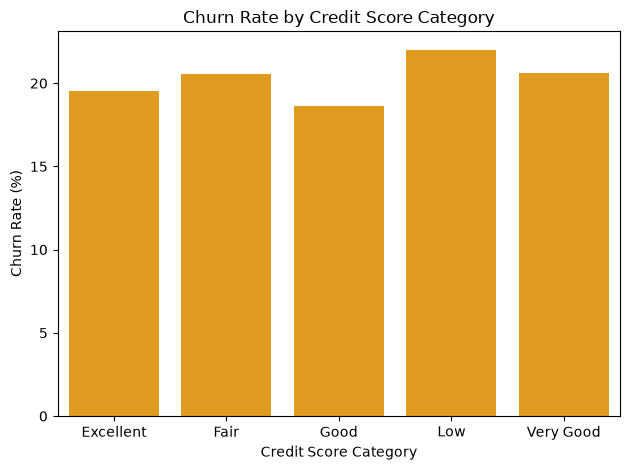

In [35]:

churn_credit = df.groupby("CredscoreCategory")["Exited"].mean().reset_index()


churn_credit["Exited"] = churn_credit["Exited"] * 100


sns.barplot(data=churn_credit, x="CredscoreCategory", y="Exited", color="orange")

plt.xlabel("Credit Score Category")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Credit Score Category")
plt.tight_layout()
plt.show()

In [36]:
df["Tenure"].value_counts()

Tenure
2     1048
1     1035
7     1028
8     1025
5     1012
3     1009
4      989
9      984
6      967
10     490
0      413
Name: count, dtype: int64

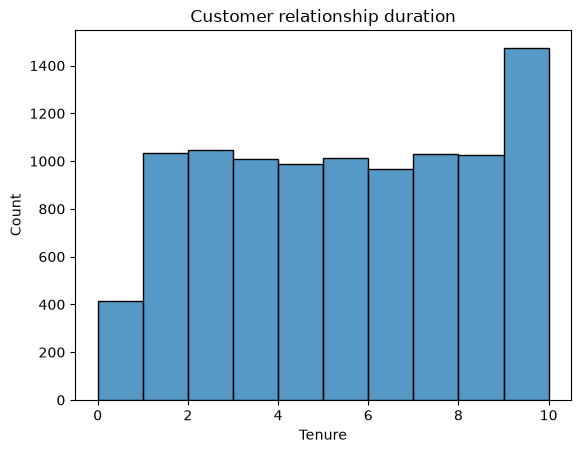

In [37]:
sns.histplot(data=df,x="Tenure",bins=10)
plt.title("Customer relationship duration")
plt.show()

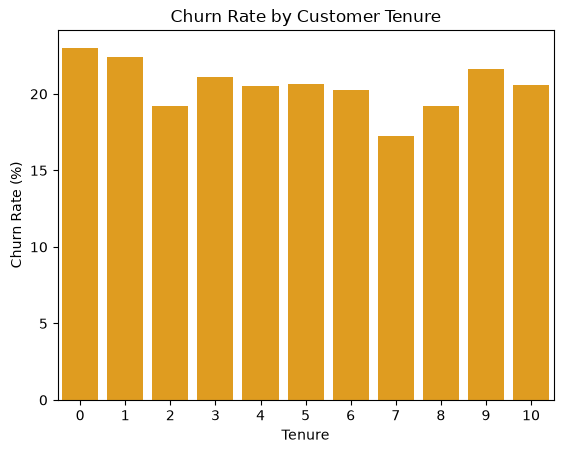

In [38]:
churn_ten = df.groupby("Tenure")["Exited"].mean().reset_index()


churn_ten["Exited"] = churn_ten["Exited"] * 100


sns.barplot(data=churn_ten, x="Tenure", y="Exited", color="orange")

plt.xlabel("Tenure")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Customer Tenure")


plt.show()

In [39]:
df['NumOfProducts'].value_counts()

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

<Axes: xlabel='NumOfProducts', ylabel='count'>

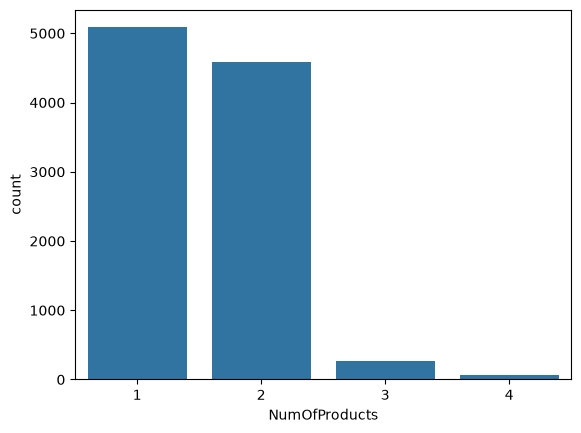

In [40]:
sns.countplot(data=df, x='NumOfProducts')

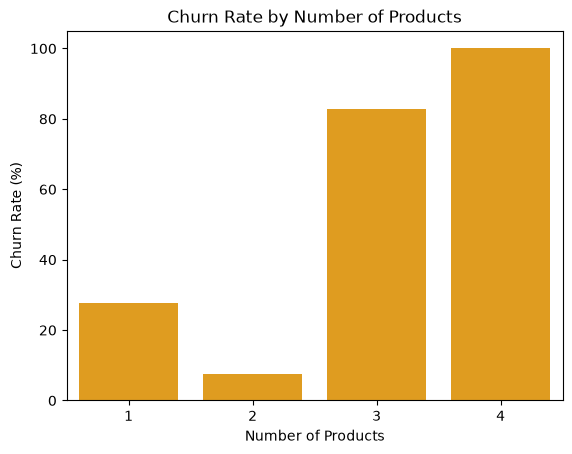

In [41]:
churn_product = df.groupby("NumOfProducts")["Exited"].mean().reset_index()

churn_product["Exited"] *= 100

sns.barplot(
    data=churn_product,
    x="NumOfProducts",
    y="Exited",
    color="orange"
)

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.show()

In [42]:
df["HasCrCard"].value_counts()

HasCrCard
1    7055
0    2945
Name: count, dtype: int64

<Axes: xlabel='HasCrCard', ylabel='count'>

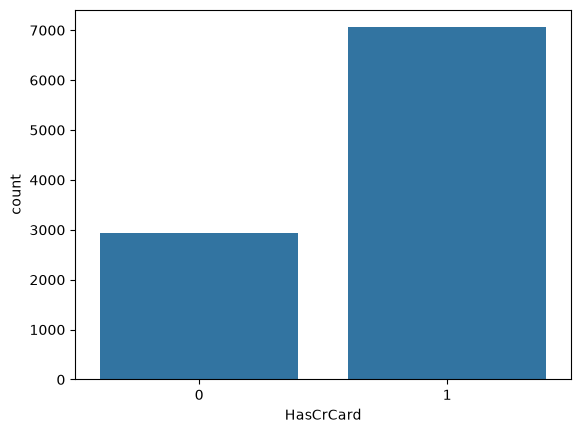

In [43]:
sns.countplot(data=df, x="HasCrCard")

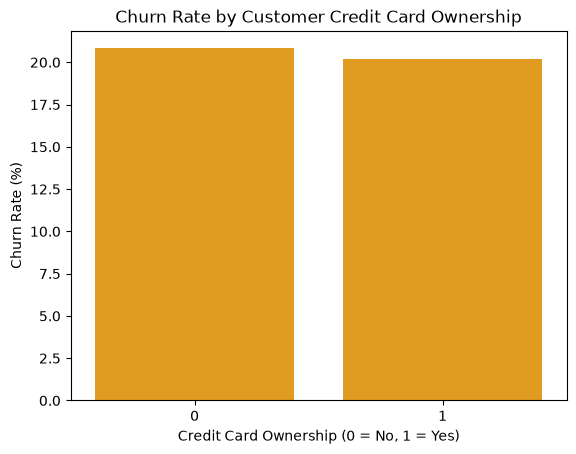

In [44]:
churn_cr = df.groupby("HasCrCard")["Exited"].mean().reset_index()

churn_cr["Exited"] = churn_cr["Exited"] * 100

sns.barplot(data=churn_cr, x="HasCrCard", y="Exited", color="orange")

plt.xlabel("Credit Card Ownership (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Customer Credit Card Ownership")

plt.show()

In [45]:
df["IsActiveMember"].value_counts()

IsActiveMember
1    5151
0    4849
Name: count, dtype: int64

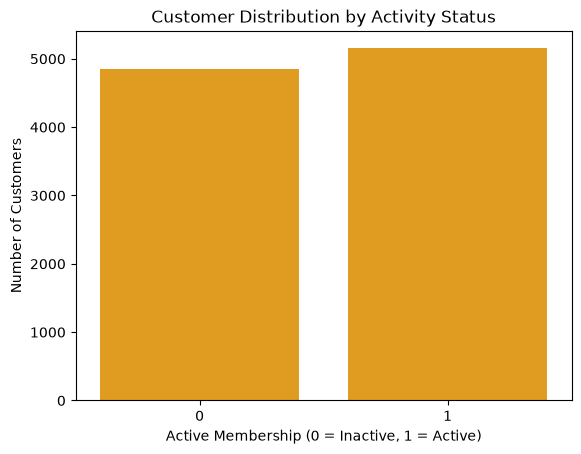

In [46]:
sns.countplot(data=df, x="IsActiveMember", color="orange")

plt.xlabel("Active Membership (0 = Inactive, 1 = Active)")
plt.ylabel("Number of Customers")
plt.title("Customer Distribution by Activity Status")

plt.show()

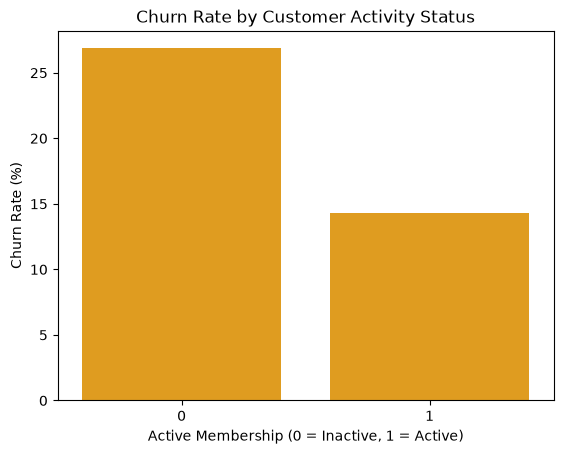

In [47]:
churn_active = df.groupby("IsActiveMember")["Exited"].mean().reset_index()

churn_active["Exited"] = churn_active["Exited"] * 100

sns.barplot(data=churn_active, x="IsActiveMember", y="Exited", color="orange")

plt.xlabel("Active Membership (0 = Inactive, 1 = Active)")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Customer Activity Status")

plt.show()

In [48]:
#Customer Retention 
df.groupby("IsActiveMember")["Exited"].apply(
    lambda x: (x == 0).mean() * 100
).reset_index()

,IsActiveMember,Exited
0,0,73.149103
1,1,85.730926


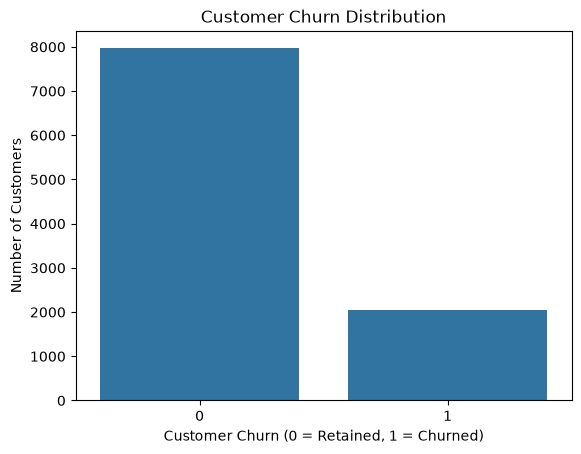

In [49]:
sns.countplot(data=df,x="Exited")
plt.xlabel("Customer Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.title("Customer Churn Distribution")

plt.show()


In [50]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeGroup,CredscoreCategory
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,36-45,Fair
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,36-45,Fair
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,36-45,Low
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,36-45,Good
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,36-45,Excellent


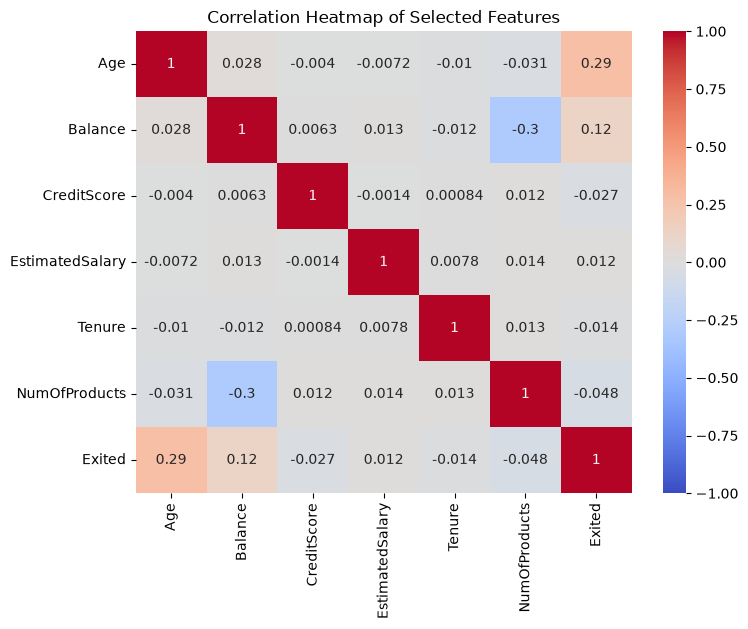

In [51]:
corr = df[["Age", "Balance" ,"CreditScore","EstimatedSalary" ,"Tenure" ,"NumOfProducts","Exited"]].corr()


plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Selected Features")
plt.show()

In [52]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate Customer IDs:", df["CustomerId"].duplicated().sum())

print("Unique customers:", df["CustomerId"].nunique())

Duplicate rows: 0
Duplicate Customer IDs: 0
Unique customers: 10000


In [53]:
zero_balance = (df["Balance"] == 0).sum()

print("Zero balance customers:", zero_balance)
print("Percentage:", zero_balance / len(df) * 100)

Zero balance customers: 3617
Percentage: 36.17


In [54]:
#consolidated comparison
profile = df.groupby("Exited")[
    [
        "Age",
        "Balance",
        "EstimatedSalary",
        "CreditScore",
        "NumOfProducts",
        "Tenure"
    ]
].mean().T

profile.columns = ["Retained", "Churned"]

profile

,Retained,Churned
Age,37.408389,44.837997
Balance,72745.296779,91108.539337
EstimatedSalary,99738.391772,101465.677531
CreditScore,651.853196,645.351497
NumOfProducts,1.544267,1.475209
Tenure,5.033279,4.932744


**Customer Value and Churn Risk Matrix Analysis**

In [55]:
median_balance=df["Balance"].median()
print("Median Balance:", median_balance)

Median Balance: 97198.54000000001


In [56]:
df['Customer_value']=np.where(df["Balance"]>=median_balance,"High_value","low_value")


In [57]:
df["RiskStatus"] = df["Exited"].map({
    0: "Low Risk",
    1: "High Risk"
})

In [58]:
df["CustomerSegment"] = (
    df["Customer_value"] + " - " + df["RiskStatus"]
)


In [59]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeGroup,CredscoreCategory,Customer_value,RiskStatus,CustomerSegment
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,36-45,Fair,low_value,High Risk,low_value - High Risk
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,36-45,Fair,low_value,Low Risk,low_value - Low Risk
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,36-45,Low,High_value,High Risk,High_value - High Risk
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,36-45,Good,low_value,Low Risk,low_value - Low Risk
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,36-45,Excellent,High_value,Low Risk,High_value - Low Risk


In [60]:
segment_counts = df["CustomerSegment"].value_counts()

print(segment_counts)

CustomerSegment
low_value - Low Risk      4212
High_value - Low Risk     3751
High_value - High Risk    1249
low_value - High Risk      788
Name: count, dtype: int64


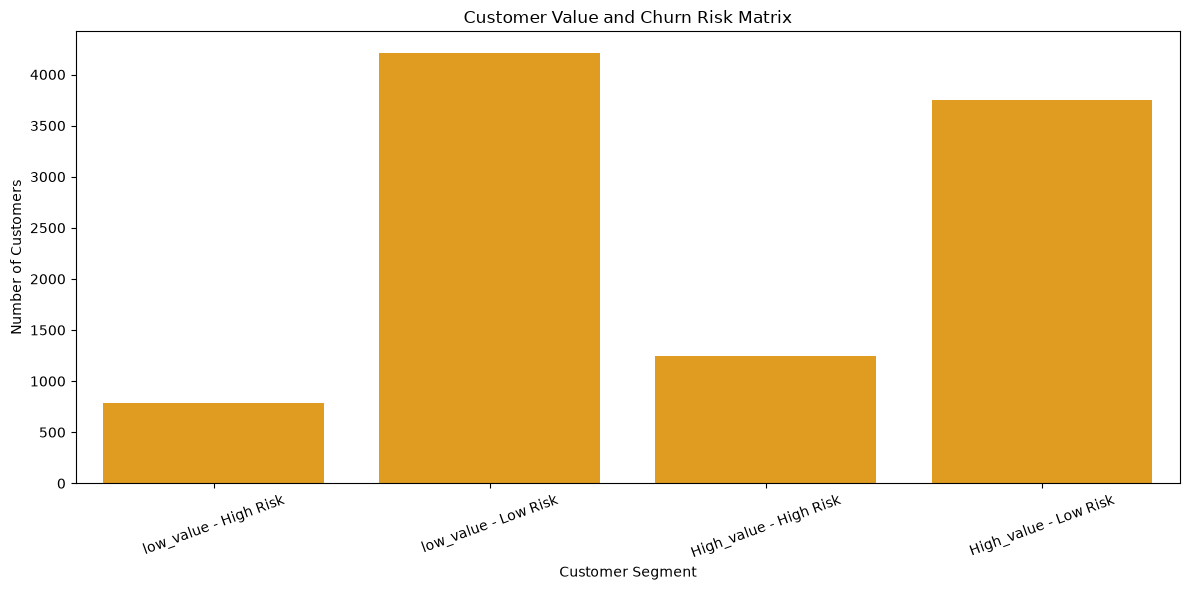

In [61]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="CustomerSegment",
    color="orange"
)

plt.title("Customer Value and Churn Risk Matrix")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

**Feature Engineering**

In [62]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeGroup,CredscoreCategory,Customer_value,RiskStatus,CustomerSegment
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,36-45,Fair,low_value,High Risk,low_value - High Risk
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,36-45,Fair,low_value,Low Risk,low_value - Low Risk
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,36-45,Low,High_value,High Risk,High_value - High Risk
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,36-45,Good,low_value,Low Risk,low_value - Low Risk
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,36-45,Excellent,High_value,Low Risk,High_value - Low Risk


In [63]:
df_train=df.iloc[:,0:14]
df_train.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [64]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [65]:
df_train.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [66]:
df_train = df_train.drop(
    columns=["RowNumber", "CustomerId", "Surname"]
)

In [67]:
df_train["HasZeroBalance"] = (
    df_train["Balance"] == 0
).astype(int)

In [68]:
df_train.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,HasZeroBalance
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,0
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,1
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0


In [69]:
df_train["Geography"].unique()

<StringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str

In [70]:
df_train["Gender"].unique()

<StringArray>
['Female', 'Male']
Length: 2, dtype: str

In [71]:
X=df_train.drop(columns=["Exited"])
y=df_train["Exited"]

In [72]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder


In [73]:
transformer = ColumnTransformer(
    transformers=[
        ('geo_ohe',
         OneHotEncoder(drop='first', sparse_output=False),
         ['Geography']),
        
        ('gender_ohe',
         OneHotEncoder(drop='first', sparse_output=False),
         ['Gender'])
    ],
    
    remainder='passthrough')                      # 'passthroug' for keeping all the columns

In [74]:
X_transformed = transformer.fit_transform(X)

In [75]:
X_transformed = pd.DataFrame(
    X_transformed,
    columns=transformer.get_feature_names_out(),
    index=X.index
)

In [76]:
X_transformed.head()

,geo_ohe__Geography_Germany,geo_ohe__Geography_Spain,gender_ohe__Gender_Male,remainder__CreditScore,remainder__Age,remainder__Tenure,remainder__Balance,remainder__NumOfProducts,remainder__HasCrCard,remainder__IsActiveMember,remainder__EstimatedSalary,remainder__HasZeroBalance
0,0.0,0.0,0.0,619.0,42.0,2.0,0.00,1.0,1.0,1.0,101348.88,1.0
1,0.0,1.0,0.0,608.0,41.0,1.0,83807.86,1.0,0.0,1.0,112542.58,0.0
2,0.0,0.0,0.0,502.0,42.0,8.0,159660.80,3.0,1.0,0.0,113931.57,0.0
3,0.0,0.0,0.0,699.0,39.0,1.0,0.00,2.0,0.0,0.0,93826.63,1.0
4,0.0,1.0,0.0,850.0,43.0,2.0,125510.82,1.0,1.0,1.0,79084.10,0.0


**RANDOM FOREST**

In [77]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X_transformed,y,test_size=0.3,random_state=42)

In [78]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import accuracy_score
 

In [79]:
rf = RandomForestClassifier(random_state=42)

param_grid = {
    "n_estimators": [200, 300],
    "max_depth": [None, 15],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 4],
    "max_features": ["sqrt"],
    "class_weight": [None, "balanced"]
}

In [80]:
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 32 candidates, totalling 160 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': [None, 'balanced'], 'max_depth': [None, 15], 'max_features': ['sqrt'], 'min_samples_leaf': [1, 4], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_

In [81]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'class_weight': 'balanced', 'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation F1 Score:
0.6237575214684984


In [82]:
best_rf = grid_search.best_estimator_

y_pred = best_rf.predict(X_test)

y_prob = best_rf.predict_proba(X_test)[:, 1]

In [83]:
print("Accuracy:",f"{accuracy_score(y_test, y_pred)*100:.2f}%")


Accuracy: 83.03%


**XGBoost**

In [84]:
from xgboost import XGBClassifier

In [85]:
xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    n_jobs=1
)

param_grid = {
    'n_estimators': [200, 300],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [86]:
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 32 candidates, totalling 160 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5], 'n_estimators': [200, 300], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_mo

In [87]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}

Best Cross-Validation F1 Score:
0.5913543387343274


In [88]:
best_xgb = grid_search.best_estimator_

y_pred = best_xgb.predict(X_test)

y_prob = best_xgb.predict_proba(X_test)[:, 1]

In [89]:
print("Accuracy:", f"{accuracy_score(y_test, y_pred)*100:.2f}%")

Accuracy: 86.90%


**Customer Segmentaion Using Kmeans**

In [90]:
X_transformed.head()

,geo_ohe__Geography_Germany,geo_ohe__Geography_Spain,gender_ohe__Gender_Male,remainder__CreditScore,remainder__Age,remainder__Tenure,remainder__Balance,remainder__NumOfProducts,remainder__HasCrCard,remainder__IsActiveMember,remainder__EstimatedSalary,remainder__HasZeroBalance
0,0.0,0.0,0.0,619.0,42.0,2.0,0.00,1.0,1.0,1.0,101348.88,1.0
1,0.0,1.0,0.0,608.0,41.0,1.0,83807.86,1.0,0.0,1.0,112542.58,0.0
2,0.0,0.0,0.0,502.0,42.0,8.0,159660.80,3.0,1.0,0.0,113931.57,0.0
3,0.0,0.0,0.0,699.0,39.0,1.0,0.00,2.0,0.0,0.0,93826.63,1.0
4,0.0,1.0,0.0,850.0,43.0,2.0,125510.82,1.0,1.0,1.0,79084.10,0.0


In [91]:
cols = [
    'remainder__Age',
    'remainder__Balance',
    'remainder__NumOfProducts',
    'remainder__IsActiveMember',
    'remainder__HasZeroBalance',
]

X_cluster = X_transformed[cols]
X_kmean=X_transformed[cols]

In [92]:
X_kmean.head()

,remainder__Age,remainder__Balance,remainder__NumOfProducts,remainder__IsActiveMember,remainder__HasZeroBalance
0,42.0,0.00,1.0,1.0,1.0
1,41.0,83807.86,1.0,1.0,0.0
2,42.0,159660.80,3.0,0.0,0.0
3,39.0,0.00,2.0,0.0,1.0
4,43.0,125510.82,1.0,1.0,0.0


In [93]:

from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
scaled=sc.fit_transform(X_kmean)

In [94]:
#Applying kmeans clustering
from sklearn.cluster import KMeans

In [95]:
k_n=range(2,10)
ssc=[]

for i in k_n:
    km=KMeans(n_clusters=i)
    km.fit(scaled)
    ssc.append(km.inertia_)

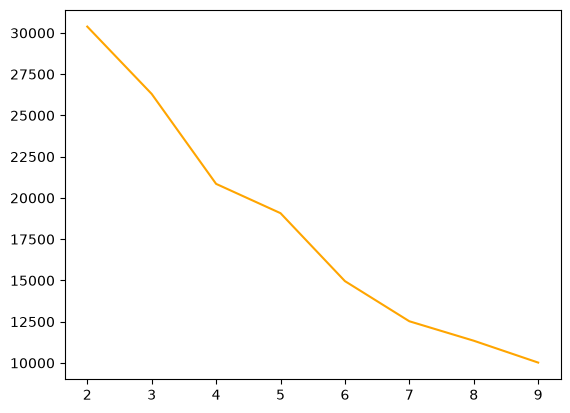

In [96]:
plt.plot(k_n,ssc,color='orange')
plt.show()

2 0.401
3 0.369
4 0.381
5 0.387
6 0.417
7 0.45
8 0.459
9 0.476


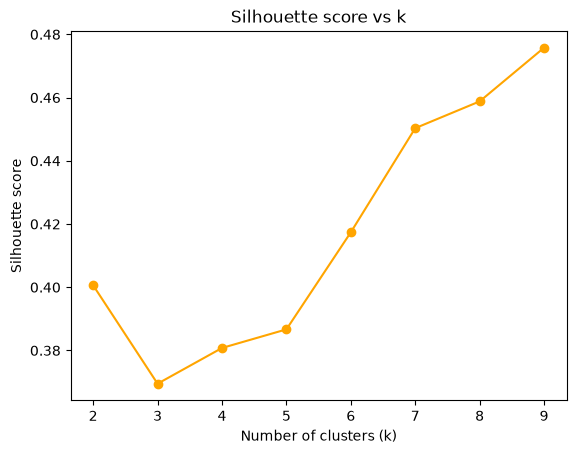

In [97]:
from sklearn.metrics import silhouette_score

sil_scores = []
for i in k_n:                      # k_n = range(2, 10) from your notebook
    km = KMeans(n_clusters=i, n_init=10, random_state=42)
    labels = km.fit_predict(scaled)
    sil_scores.append(silhouette_score(scaled, labels))
    print(i, round(sil_scores[-1], 3))

plt.plot(k_n, sil_scores, marker='o', color='orange')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score vs k")
plt.show()

In [98]:
k_means = KMeans(n_clusters=3, n_init=10, random_state=42)
k_means.fit(scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 5)","[[ 0.

In [99]:
k_means.labels_

array([2, 0, 1, ..., 2, 1, 1], shape=(10000,), dtype=int32)

In [100]:
k_means.labels_.shape

(10000,)

In [101]:
X_kmean["Clusters"]=(k_means.labels_)
X_kmean.head()

,remainder__Age,remainder__Balance,remainder__NumOfProducts,remainder__IsActiveMember,remainder__HasZeroBalance,Clusters
0,42.0,0.00,1.0,1.0,1.0,2
1,41.0,83807.86,1.0,1.0,0.0,0
2,42.0,159660.80,3.0,0.0,0.0,1
3,39.0,0.00,2.0,0.0,1.0,2
4,43.0,125510.82,1.0,1.0,0.0,0


In [102]:
X_kmean['Clusters'].value_counts()

Clusters
2    3618
0    3278
1    3104
Name: count, dtype: int64

In [103]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
pca_data=pca.fit_transform(scaled)

In [104]:
pca_data

array([[ 1.32297651,  0.95867658],
       [-0.91513346,  0.81751998],
       [-0.4357874 , -0.59108277],
       ...,
       [ 1.34998298,  0.55691012],
       [-0.19815233, -0.54450933],
       [-1.35680054, -1.49610643]], shape=(10000, 2))

In [105]:
X_kmean['PCA1'],X_kmean['PCA2']=pca_data[:,0],pca_data[:,1]
X_kmean.head()

,remainder__Age,remainder__Balance,remainder__NumOfProducts,remainder__IsActiveMember,remainder__HasZeroBalance,Clusters,PCA1,PCA2
0,42.0,0.00,1.0,1.0,1.0,2,1.322977,0.958677
1,41.0,83807.86,1.0,1.0,0.0,0,-0.915133,0.817520
2,42.0,159660.80,3.0,0.0,0.0,1,-0.435787,-0.591083
3,39.0,0.00,2.0,0.0,1.0,2,1.966712,-0.674994
4,43.0,125510.82,1.0,1.0,0.0,0,-1.359909,0.933311


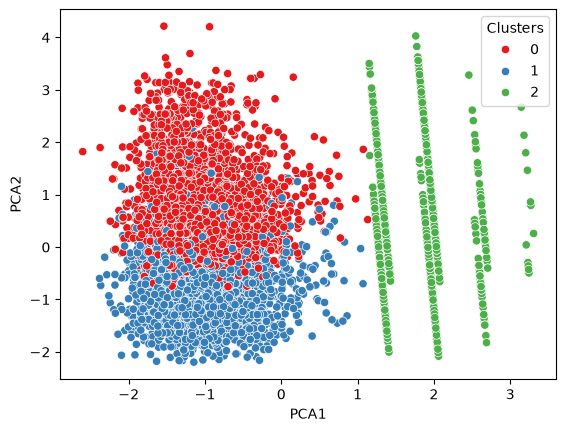

In [106]:
sns.scatterplot(x='PCA1',y='PCA2',data=X_kmean,hue='Clusters',palette='Set1')
plt.show()

In [107]:
X_kmean["Exited"] = y.values
print(X_kmean.groupby("Clusters")["Exited"].agg(["count", "mean"]))

          count      mean
Clusters                 
0          3278  0.169311
1          3104  0.316044
2          3618  0.138474


In [108]:
#agg() stands for Aggregate in Pandas.
#It allows you to apply one or multiple statistical operations to a column or multiple columns at the same time.

**Cluster Profile According to cluster behaviour**

In [117]:
cluster_profile = X_kmean.groupby("Clusters").agg(
    Customer_Count=("Clusters", "count"),
    Average_Age=("remainder__Age", "mean"),
    Average_Balance=("remainder__Balance", "mean"),
    Median_Balance=("remainder__Balance", "median"),
    Average_Products=("remainder__NumOfProducts", "mean"),
    Active_Member_Rate=("remainder__IsActiveMember", "mean"),
    Zero_Balance_Rate=("remainder__HasZeroBalance", "mean"),
    Churn_Rate=("Exited", "mean")
)

rate_cols = [
    "Active_Member_Rate",
    "Zero_Balance_Rate",
    "Churn_Rate"
]

cluster_profile[rate_cols] *= 100

cluster_profile = cluster_profile.round(2)

cluster_profile

,Customer_Count,Average_Age,Average_Balance,Median_Balance,Average_Products,Active_Member_Rate,Zero_Balance_Rate,Churn_Rate
Clusters,,,,,,,,
0,3278,39.84,119229.50,119624.57,1.38,100.00,0.00,16.93
1,3104,38.52,120482.51,120135.42,1.39,0.00,0.00,31.60
2,3618,38.44,12.95,0.00,1.79,51.77,99.97,13.85


In [ ]:
# Function to assign business names based on cluster behaviour

def assign_cluster_name(cluster):

    if cluster == 0:
        return "Active Balance-Holding Customers"

    elif cluster == 1:
        return "Inactive Balance-Holding Customers"

    elif cluster == 2:
        return "Predominantly Zero-Balance Customers"

    else:
        return "Unknown Cluster"


# Add cluster names to individual customer records
X_kmean["Cluster_Name"] = X_kmean["Clusters"].apply(assign_cluster_name)


# Add cluster names to the cluster profile table
cluster_profile["Cluster_Name"] = cluster_profile.index.map(assign_cluster_name)

cluster_profile

,Customer_Count,Average_Age,Average_Balance,Median_Balance,Average_Products,Active_Member_Rate,Zero_Balance_Rate,Churn_Rate,Cluster_Name
Clusters,,,,,,,,,
0,3278,39.84,119229.50,119624.57,1.38,100.00,0.00,16.93,Active Balance-Holding Customers
1,3104,38.52,120482.51,120135.42,1.39,0.00,0.00,31.60,Inactive Balance-Holding Customers
2,3618,38.44,12.95,0.00,1.79,51.77,99.97,13.85,Predominantly Zero-Balance Customers


In [119]:
X_kmean.head()

,remainder__Age,remainder__Balance,remainder__NumOfProducts,remainder__IsActiveMember,remainder__HasZeroBalance,Clusters,PCA1,PCA2,Exited,Cluster_Name
0,42.0,0.00,1.0,1.0,1.0,2,1.322977,0.958677,1,Predominantly Zero-Balance Customers
1,41.0,83807.86,1.0,1.0,0.0,0,-0.915133,0.817520,0,Active Balance-Holding Customers
2,42.0,159660.80,3.0,0.0,0.0,1,-0.435787,-0.591083,1,Inactive Balance-Holding Customers
3,39.0,0.00,2.0,0.0,1.0,2,1.966712,-0.674994,0,Predominantly Zero-Balance Customers
4,43.0,125510.82,1.0,1.0,0.0,0,-1.359909,0.933311,0,Active Balance-Holding Customers


**Model Dumping**

In [120]:
import joblib
import sklearn
import xgboost

In [122]:
import joblib

# 1. Create cluster names using your existing function

cluster_names = {
    0: assign_cluster_name(0),
    1: assign_cluster_name(1),
    2: assign_cluster_name(2)
}


# 2. Define K-Means features (same as your notebook)

cluster_features = [
    "remainder__Age",
    "remainder__Balance",
    "remainder__NumOfProducts",
    "remainder__IsActiveMember",
    "remainder__HasZeroBalance"
]


# 3. Collect all required objects

model_artifacts = {

    # Preprocessing
    "transformer": transformer,

    # XGBoost model
    "churn_model": best_xgb,
    "churn_model_name": "XGBoost",

    # K-Means objects
    "scaler": sc,
    "kmeans": k_means,

    # Cluster information
    "cluster_names": cluster_names,
    "cluster_features": cluster_features,
    "cluster_profile": cluster_profile,

    # Feature information
    "raw_input_columns": list(X.columns),
    "transformed_feature_names": list(transformer.get_feature_names_out()),

    # Categories
    "categories": {
        "Geography": ["France", "Spain", "Germany"],
        "Gender": ["Female", "Male"]
    },

    # Classification threshold
    "threshold": 0.5
}


# 4. Save everything

joblib.dump(
    model_artifacts,
    "banking_customer_app.pkl",
    compress=3
)

print("All required objects successfully saved!")

All required objects successfully saved!
